# Reproducibility

### 1. On `lab`:

The results in the paper used

```
python==3.12.9
numpy==2.2.4
scipy==1.15.2
numba==1.6.0
```

In `_continuation_algebraic.py` set:

```
# Option 1. Use this version for diffusion example
from ._continuation_algebraic_diffusion import sample_z_joukowski, \
        filter_z_away_from_cuts, fit_polynomial_relation, eval_P

# Option 2. This version fixes moment constrains on orthogonal basis
# from ._continuation_algebraic import sample_z_joukowski, \
#         filter_z_away_from_cuts, fit_polynomial_relation, eval_P
```

Then reinstall `pip install .`

Launch Jupyter with:

```
$ cd freealg/notebooks
$ jupyter-lab --no-browser --port=8887
```

In the cell below, note the the oupout of `np.show_runtime()`, might be something like:

    'architecture': 'Haswell'
    'num_threads': 8

Run this notebook as normal with the cell that calls `af.fit()` and saves coeffs like:

    numpy.save("af_coeffs.npy", af.coeffs)

### 2. On `mm340`:

All runtimes where performed on `mm340` machine with 48 processors `Intel(R) Xeon(R) Gold 6126 CPU @ 2.60GHz`. To reproduce the same runtimes, use this machine.

Copy `af_coeffs.npy` to `mm340:~/work/freealg/notebooks`.

Launch Jupyter to match the archetecture (like Haswell) and num_threads (like 8), same as above:

```
$ cd freealg/notebooks
$ OPENBLAS_CORETYPE=HASWELL OPENBLAS_NUM_THREADS=8 jupyter-lab --no-browser --port=8889
```

Then in the cell belew check the output of `numpy.show_runtime()` if these are set:

    'architecture': 'Haswell'
    'num_threads': 8

Run the notebook, but do not make `af.fit()` call. Rather, load `af_coeffs.npy` (see dedicated cell) and set `af.coeffs` with this loaded variable.

In [26]:
import sys
import numpy

print(sys.executable)
numpy.show_runtime()

/home/eecs/sameli/programs/miniconda3/bin/python3.13
[{'numpy_version': '2.2.4',
  'python': '3.13.16 | packaged by Anaconda, Inc. | (main, Oct  1 2026, '
            '20:24:22) [GCC 14.3.0]',
  'uname': uname_result(system='Linux', node='mm340', release='6.8.0-147-generic', version='#147-Ubuntu SMP PREEMPT_DYNAMIC Thu Sep 24 11:33:16 UTC 2026', machine='x86_64')},
 {'simd_extensions': {'baseline': ['SSE', 'SSE2', 'SSE3'],
                      'found': ['SSSE3',
                                'SSE41',
                                'POPCNT',
                                'SSE42',
                                'AVX',
                                'F16C',
                                'FMA3',
                                'AVX2',
                                'AVX512F',
                                'AVX512CD',
                                'AVX512_SKX'],
                      'not_found': ['AVX512_KNL',
                                    'AVX512_KNM',
               

In [3]:
import numpy
import scipy
from os.path import join
import matplotlib.pyplot as plt
import texplot
import matplotlib.ticker as mticker

# Imports from freealg
import freealg
from freealg import AlgebraicForm
from freealg.visualization import plot_flow, plot_mass, ridgeplot, plot_edges
from freealg.visualization._api_plot_util import _k_pow2_formatter

# Plotting options
plot_dir = './plots'
save_filename = 'diffusion'
latex = True

# Diffusion Model

Data's ESD replicates Fig 4 (right panel) of:

* [Why Diffusion Models Don’t Memorize: The Role of Implicit Dynamical Regularization in Training](https://openreview.net/pdf?id=BSZqpqgqM0)

The data is the matrix $\mathbf{U}$ in the above paper, here generated at the size $64K \times 64K$.

The input file loaded below (`Umatrix64k_eigs.npz`) contains a list of numpy arrays. Each array is the eigenvalues of a sumbatrix, ranging from the size $1K, 2K, 4K, \dots, 64K$.

Idx   Size   Repeat
---  -----   ------
0     1000       16
1     1414       11
2     2000        8
3     2828        5
4     4000        4
5     5656        2
6     8000        2
7    11313        1
8    16000        1
9    22627        1
10   32000        1
11   45254        1
12   64000        1

proc name: Intel(R) Xeon(R) Gold 6126 CPU @ 2.60GHz
num proc:  48
date:      2026-04-14 03:26:08 PDT



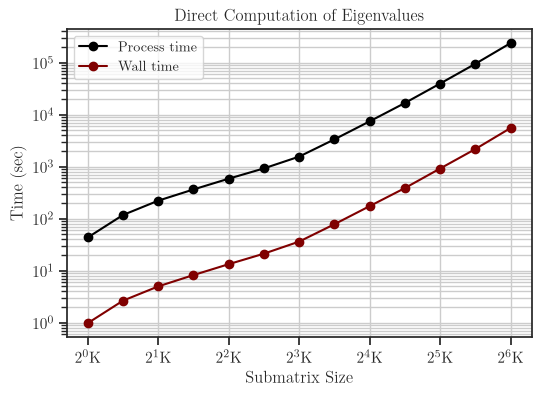

In [4]:
# Load input file
# filename = 'Umatrix64k_eigs_old.npz'
# filename = 'Umatrix64k_eigs_lsh.npz'                 # on lsh's machine
# filename = 'Umatrix64k_eigs.npz'                      # float32
filename = 'Umatrix64k_eigs_half.npz'                 # float32
# filename = 'Umatrix64kf3.2n100d0.01t_eigs.npz'          # float64
dir_ = '/data/sameli/free-algebraic'
# dir_ = '/home/sia/work/scripts/free/Xperimental/hessian'
data = numpy.load(join(dir_, filename), allow_pickle=True)
out = data['out'].item()

# Extract variables
sizes = out['sizes']                 # List of sizes of the submatrices
repeats = out['repeats']             # Repeats of sampling
eigs_repeated = out['eigs']          # List of eigenvalues per each submatrix
eigs = out['eigs']                   # List of eigenvalues per each submatrix
wall_times = out['wall_times']       # List of wall times taken to compute eigenvalues
proc_times = out['proc_times']       # List of CPU process times taken to compute eigenvalues
n, p = out['shape']                  # Dimension of the original matrix (largest matrix)
proc_name = out['proc_name']
num_proc = out['num_proc']
date = out['date']

# concatenate all repeats
max_repeat = 2
eigs = [None] * len(eigs_repeated)
for i in range(len(eigs_repeated)):
    rep_size = min(eigs_repeated[i].shape[0], max_repeat)
    eigs[i] = eigs_repeated[i][:rep_size, :].ravel()
    # s = eigs_repeated[i].shape[0]
    # shift = min(s-1, 2)
    # eigs[i] = eigs_repeated[i][shift:shift+rep_size, :].ravel()

# Sizes of submatrices
print('Idx   Size   Repeat')
print('---  -----   ------')
for i in range(sizes.size):
    print(f'{i:<2d}  {sizes[i]:>6d}  {repeats[i]:>7d}')
print('')
print(f'proc name: {proc_name}')
print(f'num proc:  {num_proc}')
print(f'date:      {date}')
print('')

# Plot wall and process times
with texplot.theme(use_latex=latex):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(sizes, proc_times, '-o', color='black', label='Process time')
    ax.plot(sizes, wall_times, '-o', color='maroon', label='Wall time')
    ax.set_xlabel('Submatrix Size')
    ax.set_ylabel('Time (sec)')
    ax.set_title('Direct Computation of Eigenvalues')
    ax.legend(fontsize='small')
    ax.set_xscale('log', base=2)
    ax.xaxis.set_major_locator(mticker.LogLocator(base=2, subs=(1000/512.0,)))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(_k_pow2_formatter))
    ax.set_yscale('log')
    ax.grid(True, which='both')
    plt.show()

In [4]:
proc_times

[np.float64(43.687655511),
 np.float64(118.03957486263636),
 np.float64(222.50844451675),
 np.float64(365.4118572637998),
 np.float64(588.6605426612502),
 np.float64(927.3584455390001),
 np.float64(1563.0924642535),
 np.float64(3352.2793760369987),
 np.float64(7434.573630840001),
 np.float64(16743.360314505997),
 np.float64(39561.656120012),
 np.float64(94775.33586185699),
 np.float64(237098.21625453397)]

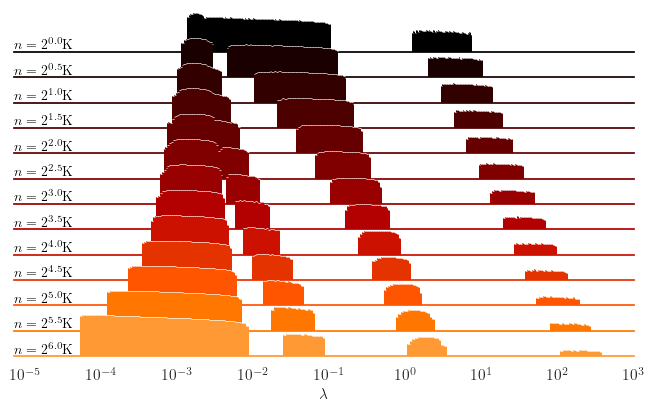

In [5]:
ridgeplot(sizes, eigs=eigs, log=True, scaley=False, hspace=-0.4,
          text_side='left', xlim=(7e-6, 1e3), figsize=(8, 4.5),
          # label_mode='pow-int',
          label_mode='pow-dec',
          latex=latex, title='',
          save=False, nbins=200)

# Fit Spectral Curve

In [5]:
# Index to choose the initial sub-matrix size
# start_idx = 2  # TEST
start_idx = 4

# Detect support from histogram
print('\n------------------------------------------')
print('Support (detected from histogram):')
support = freealg.supp(eigs[start_idx], method='hist', tol=0, nbins=150, log=True,
                      print_info=True)

# Stieltjes options (Homotopy)
stieltjes_opt = dict(
    n_levels = 200,
    max_subdivide = 20,
    anchor_mode = 'empirical',
    anchor_y_min = 1e-4,  # 1e-5~1e-6 cause left bulks to fail
    anchor_y_max = 10,
    anchor_ratio = 1,  # 0.1~1 cause stieltjes_emp to not latch to poly roots
    # anchor_match_tol = numpy.inf,  # disables anchor retry
    # anchor_ratio_tol = numpy.inf,
    anchor_match_tol = 0.05,       # retry if init anchor not mathc roots
    anchor_ratio_tol = 0.9,
    anchor_retry_factor = 3.0     # factor to multiple anchor height in retrial
)

# Inverse Stieltjes (Plemelj)
inv_stieltjes_opt = dict(
    delta = 1e-6,
    delta_ladder_ratio = 2.0,
    delta_ladder_size = 4,
    delta_ladder_grid = 'linear',   # geometric, linear
    z_query_delta = 'const',       # const, linear
    method = 'chebfit',             # direct, polyfit, chebfit, poisson
    fit_degree = 2,
    reg = 0.0,
    fit_weight = 'small_delta',  # 'uniform, small_delta
)

# Smaller delta lowers the density baseline curve 1/x^2.
af = AlgebraicForm(eigs[start_idx],
                   support=support,
                   n=sizes[start_idx],
                   log=True,
                   dtype='complex128',
                   stieltjes_opt=stieltjes_opt,
                   inv_stieltjes_opt=inv_stieltjes_opt)

# We use deg_z = 1 since we guess the data is closely related to free Levy
# model, where deg_z is always 1. We also set _deg_m = 5 to have the capacity
# of representing 4 bulks once decompressed.
print('\n------------------------------------------')

# Combinations that work
# deg_m, deg_z = 8, 5
# deg_m, deg_z = 10, 5
# deg_m, deg_z = 9, 5
# deg_m, deg_z = 8, 4
# deg_m, deg_z = 7, 3
# deg_m, deg_z = 6, 6
# deg_m, deg_z = 6, 3
# deg_m, deg_z = 5, 5
deg_m, deg_z = 7, 5  # VERY GOOG

deg_mu = 4
mu = numpy.zeros((deg_mu+1, ), dtype=float)
mu[0] = 1.0
for i in range(1, mu.size):
    if i == 1:
        mu[i] = numpy.mean(af.eig)
    else:
        mu[i] = numpy.mean(af.eig**i)


------------------------------------------
Support (detected from histogram):
| bulk 1 | interval: (  0.00072,   0.00646) | center:   0.00215 |  mass: 80.00% |
| bulk 2 | interval: (  0.03802,   0.27663) | center:   0.10255 |  mass: 17.50% |
| bulk 3 | interval: (  6.25733,  27.72341) | center:  13.17097 |  mass:  2.50% |
mass(x) ~ 0.07001 * x^(-0.3977)

------------------------------------------


### Options for Reprodicibility

Note: on `lab` machine, the encoded variable `af.coeffs` is:

```
k05VTVBZAQB2AHsnZGVzY3InOiAnPGMxNicsICdmb3J0cmFuX29yZGVyJzogRmFsc2UsICdzaGFwZSc6ICg2LCA4KSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAqSH5p1R3vtPwAAAAAAAAAAhObygNNouz8AAAAAAAAAACy0Wg04nGE/AAAAAAAAAACD6Qqx6yTvvgAAAAAAAAAANdKHR3CFYD4AAAAAAAAAgM7C+xTqE7a9AAAAAAAAAADbeRFoQITkvAAAAAAAAAAAW0Ne7yHO3DsAAAAAAAAAAIIb1vOyEKE/AAAAAAAAAIBxqam11BUGQAAAAAAAAACAQwnG6lW90z8AAAAAAAAAgG9tXgwv0HY/AAAAAAAAAIDR9GbjANz5vgAAAAAAAAAAZD7jGjB1WD4AAAAAAAAAABcwKL4ni589AAAAAAAAAABVr2OITgGoPAAAAAAAAAAA3IgQEbNwoL8AAAAAAAAAAJDnatm4Y6+/AAAAAAAAAAA6e0Rok4gAQAAAAAAAAACAe61friftyz8AAAAAAAAAgNsc4XAAkm4/AAAAAAAAAIDOBQxK1kHgvgAAAAAAAAAAeQj7UtzaLr4AAAAAAAAAAOwJh+juQVi9AAAAAAAAAAC6ERJ85tKKPwAAAAAAAACAe5R2EpLxrb8AAAAAAAAAAPsbDk2OiLm/AAAAAAAAAABffuBp03bKPwAAAAAAAAAA3DYadp4/X78AAAAAAAAAAMvNwJomQNY+AAAAAAAAAAB/gN5oCZs9vgAAAAAAAAAA3fbgDJznkj0AAAAAAAAAAEqtO3ICaSU/AAAAAAAAAACcHUWXaGGdPwAAAAAAAAAAbE7Ep0UTm78AAAAAAAAAALkyiDuJI2m/AAAAAAAAAAD1QRMQLqcDPwAAAAAAAACApBOuF2EjgL4AAAAAAAAAAKrHxGTMveg9AAAAAAAAAAC8KoOspmtBvQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAH5YPZMBaSU/AAAAAAAAAAAJl0sKvAiQPwAAAAAAAAAAJckGlfGgC78AAAAAAAAAACMsEBjP9py+AAAAAAAAAAAhD85SWs4kPgAAAAAAAAAA4MFNvfLfkr0AAAAAAAAAADDfFLEBpOo8AAAAAAAAAAA=
```

In [23]:
# OPTION 1:
# Run this cell on `lab` machine.
# This cell also saves `af_coeffs.npy`, allowing reproducibility on another
# machine with exact same coeffs (see loading on the next cell)

# coeffs = af.fit(
#     deg_m, deg_z,
#     reg=0,
#     r_min=1.8, r_max=2.2, n_r=5,
#     y_scale=1.0, gamma=1.0,
#     n_samples=4096 // 2,
#     cut_eps=0.01,
#     normalize=True,
#     triangular=(None, None),
#     mu=mu,
#     mu_reg=None, verbose=True, plot=False)
# print('')

# # Save as file (to transfer to another machine)
# numpy.save("af_coeffs.npy", af.coeffs)

# # Also encode (no need to transfer to ansother machine)
# import io
# import base64

# buf = io.BytesIO()
# numpy.save(buf, af.coeffs)
# encoded = base64.b64encode(buf.getvalue()).decode()
# print('Encoded coeffs:')
# print(encoded)

In [6]:
# OPTION 2:
# Run this cell on `mm340` machine after the file `af_coeffs.npy` was
# transferred from `lab` to `mm340` (see cell above)

# # Restore fitted coefficients
# af.coeffs = numpy.load("af_coeffs.npy")
# coeffs = af.coeffs

# # Load previously-computed coeffs for reproducibility (see above cell, Option 1)
# from freealg._algebraic_form._stieltjes_poly3 import StieltjesPoly
# from freealg._algebraic_form._moments import AlgebraicStieltjesMoments, Moments

# # Rebuild dependent objects
# af._stieltjes_poly = StieltjesPoly(
#     af.coeffs,
#     stieltjes_opt=af.stieltjes_opt,
#     stieltjes_emp=af._stieltjes_emp,
#     dtype=af.dtype
# )

# af._moments_base = AlgebraicStieltjesMoments(af.coeffs)
# af.moments = Moments(af._moments_base)

In [ ]:
# Option 3:
# Run this cell on `mm340` machine after `af.coeffs` is encodded

# Restore fitted coefficients
encoded = "k05VTVBZAQB2AHsnZGVzY3InOiAnPGMxNicsICdmb3J0cmFuX29yZGVyJzogRmFsc2UsICdzaGFwZSc6ICg2LCA4KSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAqSH5p1R3vtPwAAAAAAAAAAhObygNNouz8AAAAAAAAAACy0Wg04nGE/AAAAAAAAAACD6Qqx6yTvvgAAAAAAAAAANdKHR3CFYD4AAAAAAAAAgM7C+xTqE7a9AAAAAAAAAADbeRFoQITkvAAAAAAAAAAAW0Ne7yHO3DsAAAAAAAAAAIIb1vOyEKE/AAAAAAAAAIBxqam11BUGQAAAAAAAAACAQwnG6lW90z8AAAAAAAAAgG9tXgwv0HY/AAAAAAAAAIDR9GbjANz5vgAAAAAAAAAAZD7jGjB1WD4AAAAAAAAAABcwKL4ni589AAAAAAAAAABVr2OITgGoPAAAAAAAAAAA3IgQEbNwoL8AAAAAAAAAAJDnatm4Y6+/AAAAAAAAAAA6e0Rok4gAQAAAAAAAAACAe61friftyz8AAAAAAAAAgNsc4XAAkm4/AAAAAAAAAIDOBQxK1kHgvgAAAAAAAAAAeQj7UtzaLr4AAAAAAAAAAOwJh+juQVi9AAAAAAAAAAC6ERJ85tKKPwAAAAAAAACAe5R2EpLxrb8AAAAAAAAAAPsbDk2OiLm/AAAAAAAAAABffuBp03bKPwAAAAAAAAAA3DYadp4/X78AAAAAAAAAAMvNwJomQNY+AAAAAAAAAAB/gN5oCZs9vgAAAAAAAAAA3fbgDJznkj0AAAAAAAAAAEqtO3ICaSU/AAAAAAAAAACcHUWXaGGdPwAAAAAAAAAAbE7Ep0UTm78AAAAAAAAAALkyiDuJI2m/AAAAAAAAAAD1QRMQLqcDPwAAAAAAAACApBOuF2EjgL4AAAAAAAAAAKrHxGTMveg9AAAAAAAAAAC8KoOspmtBvQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAH5YPZMBaSU/AAAAAAAAAAAJl0sKvAiQPwAAAAAAAAAAJckGlfGgC78AAAAAAAAAACMsEBjP9py+AAAAAAAAAAAhD85SWs4kPgAAAAAAAAAA4MFNvfLfkr0AAAAAAAAAADDfFLEBpOo8AAAAAAAAAAA="
af.coeffs = numpy.load(io.BytesIO(base64.b64decode(encoded)))
coeffs = af.coeffs

# Load previously-computed coeffs for reproducibility (see above cell, Option 1)
from freealg._algebraic_form._stieltjes_poly3 import StieltjesPoly
from freealg._algebraic_form._moments import AlgebraicStieltjesMoments, Moments

# Rebuild dependent objects
af._stieltjes_poly = StieltjesPoly(
    af.coeffs,
    stieltjes_opt=af.stieltjes_opt,
    stieltjes_emp=af._stieltjes_emp,
    dtype=af.dtype
)

af._moments_base = AlgebraicStieltjesMoments(af.coeffs)
af.moments = Moments(af._moments_base)

In [ ]:
# print('\n------------------------------------------')
# print('Support (estimated from polynomial):')
# est_supp = af.support()
# for i, supp in enumerate(est_supp):
#     print(f'\tInterval {i+1}: ({supp[0]:>9.4f}, {supp[1]:>9.4f})')

# print('\n------------------------------------------')
# print('Atoms (estimated from polynomial):')
# for i, atom in enumerate(af.atoms()):
#     print(f'\tAtom {i+1}. x: {atom[0]:>4.1e}, '
#           f'weight: {100.0*atom[1]:>4.1f}%')

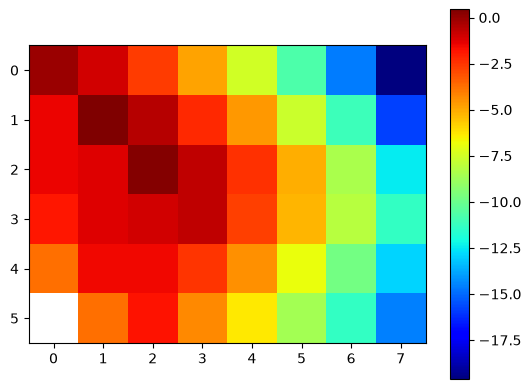

In [7]:
%matplotlib inline

p = plt.imshow(numpy.log10(numpy.abs(af.coeffs.real)), cmap=plt.cm.jet)
plt.colorbar(p)
plt.show()

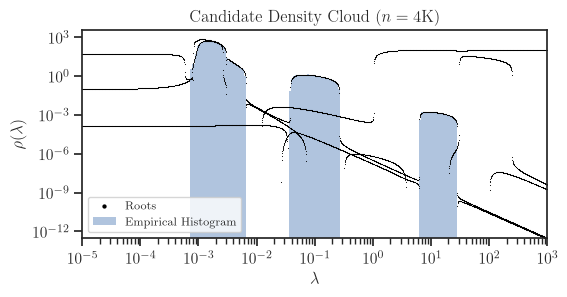

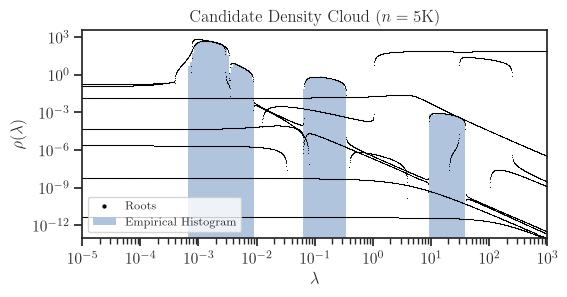

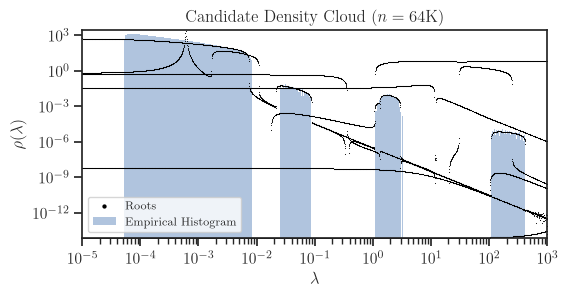

In [8]:
# Check if the density plotted above is formed by correct roots. For this,
# we plot all possible roots below.
x_min = 1e-5
x_max = 1e3
x_highres = numpy.geomspace(x_min, x_max, 2000)

# for idx in range(start_idx, sizes.size):
for idx in [start_idx, start_idx+1, sizes.size-1]:
    af.candidates(
        size=sizes[idx],
        kind='free',
        x=x_highres,
        eig=eigs[idx],
        delta=None, markersize=0.6, latex=latex)

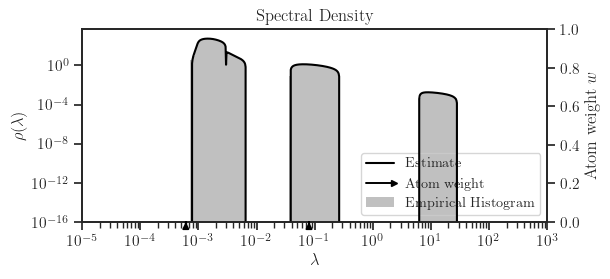


Mass: 0.99901646


In [9]:
# Plot density
x_min = 1e-5
x_max = 1e3
x0 = numpy.geomspace(x_min, x_max, 1000)
rho0 = af.density(x0, plot=True, latex=latex)

# Check mass (at start size)
print('')
mass = numpy.trapz(rho0, x0)
print(f'Mass: {mass:0.8f}')

Support (estimated from polynomial):
	Interval 1: (   0.0009,    0.0063)
	Interval 2: (   0.0385,    0.2635)
	Interval 3: (   6.2868,   28.0422)


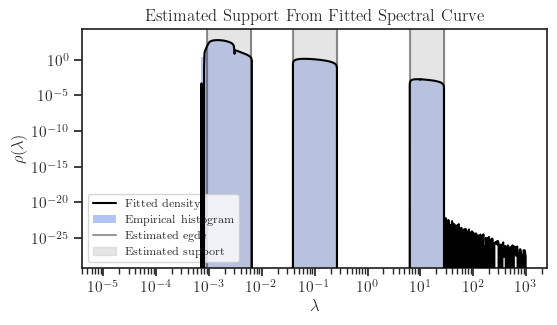

In [8]:
print('Support (estimated from polynomial):')

est_supp = af.support(refine=False, resplit_density=4, merge_threshold=0.1)

for i, supp in enumerate(est_supp):
    print(f'\tInterval {i+1}: ({supp[0]:>9.4f}, {supp[1]:>9.4f})')

with texplot.theme(use_latex=latex):
    alpha = 0.4
    fig, ax = plt.subplots(figsize=(6, 3.1))
    ax.plot(x0, rho0, color='black', zorder=10, label='Fitted density')
    
    bins = numpy.geomspace(
        numpy.min(eigs[start_idx]), numpy.max(eigs[start_idx]), 150)
    ax.hist(eigs[start_idx], bins, density=True,color='royalblue',
            alpha=0.4, zorder=1, edgecolor='none',
            label='Empirical histogram')
    
    for i in range(len(est_supp)):
        label = 'Estimated egde' if i == 0 else ''
        ax.axvline(est_supp[i][0], linestyle='-', color='black', alpha=alpha, label=label)
        ax.axvline(est_supp[i][1], linestyle='-', color='black', alpha=alpha)
    
        label = 'Estimated support' if i == 0 else ''
        ax.axvspan(est_supp[i][0], est_supp[i][1], color='silver', alpha=alpha, label=label)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    # ax.set_xlim([x[0], x[-1]])
    ax.set_xlabel(r'$\lambda$')
    ax.set_ylabel(r'$\rho(\lambda)$')
    ax.legend(fontsize='x-small', loc='lower left')
    ax.set_title('Estimated Support From Fitted Spectral Curve')
    plt.show()

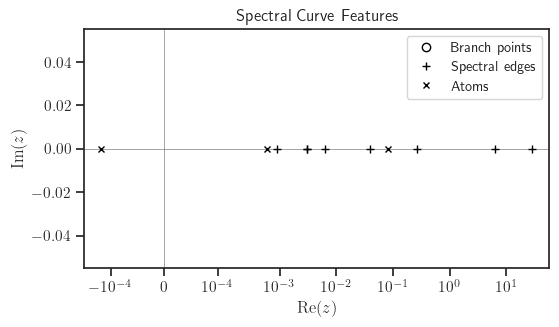


i   Branch Points        Spectral Edge
--  -------------------  -------------


In [10]:
# Branch points
bp = af.branch_points(tol=1e-16, real_tol=1e-16, plot=True, latex=latex)

# A branch point on real axis is a candidate to also be a spectral edge.
# Those with near zero imaginary part are flagged as maybe a spectral edge.
print('\ni   Branch Points        Spectral Edge')
print('--  -------------------  -------------')
for i in range(bp.size):
    print(f'{i+1}   {bp[i].real:>+8.4f}{bp[i].imag:>+5.3e}i', end='  ')
    if numpy.abs(bp[i].imag) < 1e-14:
        print('Maybe')
    else:
        print('No')

# Free Decompression

In [ ]:
# import time

# init_time = time.process_time()

# # Choosing the largest sub-matrix size to decompress to
# end_idx = sizes.size - 1

# # Subset of sizes to apply free decompression
# fd_sizes = sizes[start_idx:end_idx+1]

# # x span of decompression
# x_min = 1e-5
# x_max = 1e3
# x = numpy.geomspace(x_min, x_max, 500)

# newton_opt = dict(
#     dt_max=0.001,
#     dt_min=1e-10,
#     tol=1e-8,
#     max_iter=1000,
#     parallel=True,
#     n_jobs=48,
#     log_mode=True,
#     pair_enable=True,
#     pair_gap_factor=10.0,
# )

# # Using method of characteristics (MoC) with 2x2 Newton and
# # predictor/corrector (PC) to stabilize and speedup convergence
# rho, atoms = af.decompress(
#     fd_sizes, x=x, kind='free', method='moc', min_n_times=100,
#     newton_opt=newton_opt, return_atoms=True, atom_eps=0.0,
#     verbose=False, plot=True, latex=latex)

# fd_time = time.process_time() - init_time
# print(fd_time)

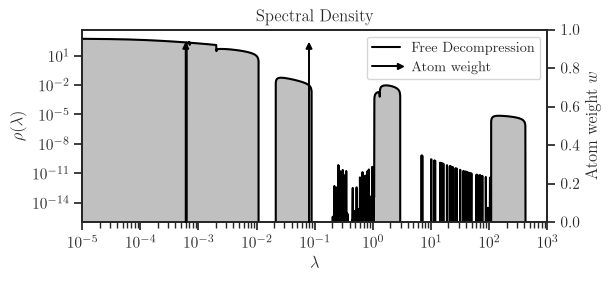

In [9]:
# Choosing the largest sub-matrix size to decompress to
end_idx = sizes.size - 1

# Subset of sizes to apply free decompression
fd_sizes = sizes[start_idx:end_idx+1]

# x span of decompression
x_min = 1e-5
x_max = 1e3
x = numpy.geomspace(x_min, x_max, 2000)

newton_opt = dict(
    dt_max=0.001,
    dt_min=1e-10,
    tol=1e-8,
    max_iter=1000,
    parallel=True,
    n_jobs=24,
    log_mode=True,
    pair_enable=True,
    pair_gap_factor=10.0,
)

# Using method of characteristics (MoC) with 2x2 Newton and
# predictor/corrector (PC) to stabilize and speedup convergence
rho, atoms = af.decompress(
    fd_sizes, x=x, kind='free', method='moc', min_n_times=100,
    newton_opt=newton_opt, return_atoms=True, atom_eps=0.0,
    verbose=False, plot=True, latex=latex)

In [10]:
rho_cut = rho.copy()
for i in range(rho_cut.shape[0]):
    rho_cut[i, x < numpy.min(eigs[start_idx + i])] = 0.0

# Ablation

In [12]:
import torch

matrix_filename = join(dir_, 'Umatrix64k.pt')

U64 = torch.load(
    matrix_filename,
    map_location='cpu',
    weights_only=False,
)

print('type:', type(U64))

if isinstance(U64, torch.Tensor):
    print('shape:', U64.shape)
    print('dtype:', U64.dtype)
    print('device:', U64.device)
    print('contiguous:', U64.is_contiguous())
elif isinstance(U64, dict):
    print('keys:', U64.keys())

type: <class 'torch.Tensor'>
shape: torch.Size([64000, 64000])
dtype: torch.float64
device: cpu
contiguous: True


In [15]:
import time
import torch

torch.set_num_threads(48)
torch.manual_seed(0)

v = torch.randn(n, dtype=U64.dtype)

# Warm-up
for _ in range(2):
    Av = torch.mv(U64, v)

# Benchmark
num_trials = 3
start = time.perf_counter()

for _ in range(num_trials):
    Av = torch.mv(U64, v)

matvec_time = (time.perf_counter() - start) / num_trials

print(f'Torch threads: {torch.get_num_threads()}')
print(f'Matvec time:   {matvec_time:.3f} sec')

Torch threads: 48
Matvec time:   0.378 sec


In [20]:
import time
import torch

@torch.no_grad()
def slq_spectral_measure(A, num_probes=8, lanczos_degree=100, seed=0):

    n = A.shape[0]
    dtype = A.dtype
    generator = torch.Generator(device=A.device)
    generator.manual_seed(seed)

    # Independent normalized Rademacher probes, processed simultaneously
    q = torch.randint(
        0, 2, (n, num_probes),
        generator=generator,
        device=A.device,
        dtype=torch.int8,
    ).to(dtype)

    q.mul_(2.0).sub_(1.0)
    q /= numpy.sqrt(n)

    q_prev = torch.zeros_like(q)
    beta_prev = torch.zeros(
        num_probes, dtype=dtype, device=A.device
    )

    alpha = torch.zeros(
        num_probes, lanczos_degree,
        dtype=dtype, device=A.device
    )
    beta = torch.zeros(
        num_probes, lanczos_degree - 1,
        dtype=dtype, device=A.device
    )

    start = time.perf_counter()

    for j in range(lanczos_degree):

        z = A @ q

        if j > 0:
            z -= q_prev * beta_prev

        alpha_j = torch.sum(q * z, dim=0)
        z -= q * alpha_j

        # Repeat local orthogonalization for numerical stability
        correction = torch.sum(q * z, dim=0)
        z -= q * correction
        alpha_j += correction

        alpha[:, j] = alpha_j

        if j < lanczos_degree - 1:
            beta_j = torch.linalg.vector_norm(z, dim=0)
            beta[:, j] = beta_j

            q_prev = q
            q = z / beta_j
            beta_prev = beta_j

        if (j + 1) % 10 == 0:
            elapsed = time.perf_counter() - start
            print(
                f'{j + 1:>3d}/{lanczos_degree} steps, '
                f'{elapsed:>7.1f} sec'
            )

    # Ritz nodes and quadrature weights
    nodes = []
    weights = []

    for probe in range(num_probes):

        T = torch.diag(alpha[probe])
        T += torch.diag(beta[probe], diagonal=1)
        T += torch.diag(beta[probe], diagonal=-1)

        theta, vectors = torch.linalg.eigh(T)

        nodes.append(theta.cpu().numpy())
        weights.append(
            (vectors[0, :]**2 / num_probes).cpu().numpy()
        )

    nodes = numpy.concatenate(nodes)
    weights = numpy.concatenate(weights)

    elapsed = time.perf_counter() - start

    print(f'\nSLQ time:          {elapsed:.2f} sec')
    print(f'Target matvecs:    {num_probes * lanczos_degree}')
    print(f'Quadrature nodes:  {nodes.size}')
    print(f'Sum of weights:    {weights.sum():.12f}')
    print(f'Node range:        ({nodes.min():.6e}, {nodes.max():.6e})')

    return nodes, weights

# Choose one of these following configs for SLQ for the rows of the table
# with various Monte-cCarlo iterations and Lanczos degrees

# Option 1:
# slq_nodes, slq_weights = slq_spectral_measure(
#     U64,
#     num_probes=8,       # SETTING
#     lanczos_degree=60,  # SETTING
#     seed=0,
# )

# Option 2:
# slq_nodes, slq_weights = slq_spectral_measure(
#     U64,
#     num_probes=8,
#     lanczos_degree=100,
#     seed=0,
# )

# Option 3:
slq_nodes, slq_weights = slq_spectral_measure(
    U64,
    num_probes=16,
    lanczos_degree=200,
    seed=0,
)

 10/200 steps,     6.6 sec
 20/200 steps,    12.5 sec
 30/200 steps,    19.0 sec
 40/200 steps,    22.8 sec
 50/200 steps,    26.8 sec
 60/200 steps,    30.7 sec
 70/200 steps,    34.7 sec
 80/200 steps,    38.4 sec
 90/200 steps,    42.2 sec
100/200 steps,    45.9 sec
110/200 steps,    49.8 sec
120/200 steps,    53.7 sec
130/200 steps,    57.5 sec
140/200 steps,    61.2 sec
150/200 steps,    65.3 sec
160/200 steps,    69.1 sec
170/200 steps,    73.0 sec
180/200 steps,    76.8 sec
190/200 steps,    80.8 sec
200/200 steps,    84.6 sec

SLQ time:          84.94 sec
Target matvecs:    3200
Quadrature nodes:  3200
Sum of weights:    1.000000000000
Node range:        (3.035553e-04, 4.219466e+02)


In [21]:
import numpy
import pandas
from scipy.stats import wasserstein_distance


def gaussian_mmd2_biased(a, b, sigma=None, max_pts=4000, seed=0):
    """Biased Gaussian MMD^2."""
    rng = numpy.random.default_rng(seed)

    a = numpy.asarray(a)
    b = numpy.asarray(b)

    if a.size > max_pts:
        a = rng.choice(a, size=max_pts, replace=False)
    if b.size > max_pts:
        b = rng.choice(b, size=max_pts, replace=False)

    a = a[:, None]
    b = b[:, None]

    if sigma is None:
        z = numpy.vstack([a, b]).ravel()
        dz = numpy.abs(z[:, None] - z[None, :])
        sigma = numpy.median(dz[dz > 0])

        if not numpy.isfinite(sigma) or sigma <= 0:
            sigma = 1.0

    k_aa = numpy.exp(-0.5 * ((a - a.T) / sigma)**2).mean()
    k_bb = numpy.exp(-0.5 * ((b - b.T) / sigma)**2).mean()
    k_ab = numpy.exp(-0.5 * ((a - b.T) / sigma)**2).mean()

    return k_aa + k_bb - 2.0 * k_ab


# Exact 64K empirical spectrum
eig_emp = numpy.asarray(eigs[end_idx], dtype=float)


# FDPM: sample from the final recovered continuous density
eig_fd = freealg.sample(
    x,
    rho_cut[-1],
    num_pts=eig_emp.size,
    method='qmc',
    seed=end_idx,
)


# SLQ: deterministic quantile sample from the weighted Ritz measure
mask = (
    numpy.isfinite(slq_nodes)
    & numpy.isfinite(slq_weights)
    & (slq_nodes > 0)
    & (slq_weights > 0)
)

nodes = numpy.asarray(slq_nodes[mask], dtype=float)
weights = numpy.asarray(slq_weights[mask], dtype=float)

order = numpy.argsort(nodes)
nodes = nodes[order]
weights = weights[order]
weights /= weights.sum()

cdf = numpy.cumsum(weights)
u = (numpy.arange(eig_emp.size) + 0.5) / eig_emp.size
indices = numpy.searchsorted(cdf, u, side='left')
eig_slq = nodes[numpy.minimum(indices, nodes.size - 1)]


def distribution_metrics(eig_est, seed):
    log_emp = numpy.log(eig_emp)
    log_est = numpy.log(eig_est)

    return {
        'W1/L': (
            wasserstein_distance(log_emp, log_est)
            / numpy.ptp(log_emp)
        ),
        'MMD': 0.5 * gaussian_mmd2_biased(
            log_emp,
            log_est,
            sigma=None,
            max_pts=4000,
            seed=seed,
        ),
    }


comparison = pandas.DataFrame({
    'FDPM': distribution_metrics(eig_fd, seed=end_idx),
    'SLQ': distribution_metrics(eig_slq, seed=end_idx),
}).T

display(
    (100.0 * comparison).style.format('{:.2f}%')
)

,W1/L,MMD
FDPM,2.31%,0.53%
SLQ,2.69%,0.47%
